In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries import is success")

Libraries import is success


In [9]:
columns = [
    "Frequency",
    "Angle of Attack",
    "Vhord Length",
    "Free_stream_velocity",
    "Suction_side_displacment_thickness",
    "Sound_pressure_level"
]

df = pd.read_csv(
    "../dataset/airfoil_self_noise.dat",
    sep = r"\s+",
    header = None,
    names = columns
)

print("Dataset loaded successfully")
print(f"Dataset shape: {df.shape}")

Dataset loaded successfully
Dataset shape: (1503, 6)


In [10]:
print("First 5 rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

First 5 rows:


,Frequency,Angle of Attack,Vhord Length,Free_stream_velocity,Suction_side_displacment_thickness,Sound_pressure_level
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1503 entries, 0 to 1502
Data columns (total 6 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Frequency                           1503 non-null   int64  
 1   Angle of Attack                     1503 non-null   float64
 2   Vhord Length                        1503 non-null   float64
 3   Free_stream_velocity                1503 non-null   float64
 4   Suction_side_displacment_thickness  1503 non-null   float64
 5   Sound_pressure_level                1503 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 70.6 KB

Statistical Summary:


,Frequency,Angle of Attack,Vhord Length,Free_stream_velocity,Suction_side_displacment_thickness,Sound_pressure_level
count,1503.000000,1503.000000,1503.000000,1503.000000,1503.000000,1503.000000
mean,2886.380572,6.782302,0.136548,50.860745,0.011140,124.835943
std,3152.573137,5.918128,0.093541,15.572784,0.013150,6.898657
min,200.000000,0.000000,0.025400,31.700000,0.000401,103.380000
25%,800.000000,2.000000,0.050800,39.600000,0.002535,120.191000
50%,1600.000000,5.400000,0.101600,39.600000,0.004957,125.721000
75%,4000.000000,9.900000,0.228600,71.300000,0.015576,129.995500
max,20000.000000,22.200000,0.304800,71.300000,0.058411,140.987000


In [11]:
X = df.drop("Sound_pressure_level", axis=1)

y = df["Sound_pressure_level"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1503, 5)
Target shape: (1503,)


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1202, 5)
Testing data: (301, 5)


In [13]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [14]:
y_pred = model.predict(X_test)

print("Actual values:")
print(y_test.head())

print("\nPredicted values:")
print(y_pred[:5])

Actual values:
51      125.045
1465    118.767
184     120.233
1000    137.047
746     134.556
Name: Sound_pressure_level, dtype: float64

Predicted values:
[124.16191238 119.71754202 120.29668459 129.615236   129.75593826]


In [15]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Evaluation Results
------------------------
MAE: 3.672414564178807
MSE: 22.128643318247352
RMSE: 4.704109194974895
R2 Score: 0.558297975489727


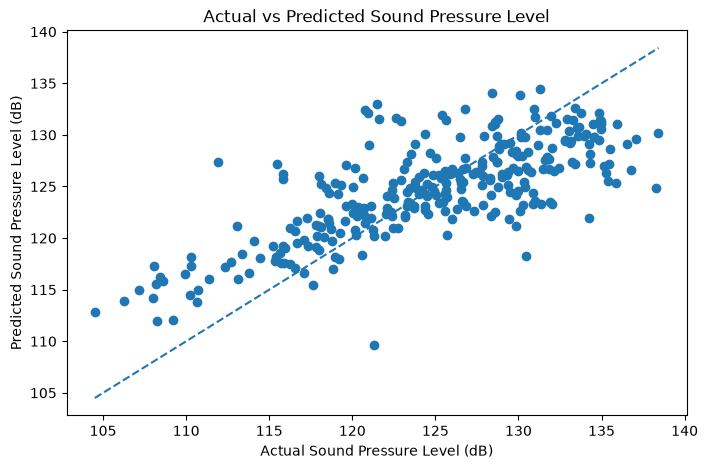

In [17]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Sound Pressure Level (dB)")
plt.ylabel("Predicted Sound Pressure Level (dB)")
plt.title("Actual vs Predicted Sound Pressure Level")

plt.show()

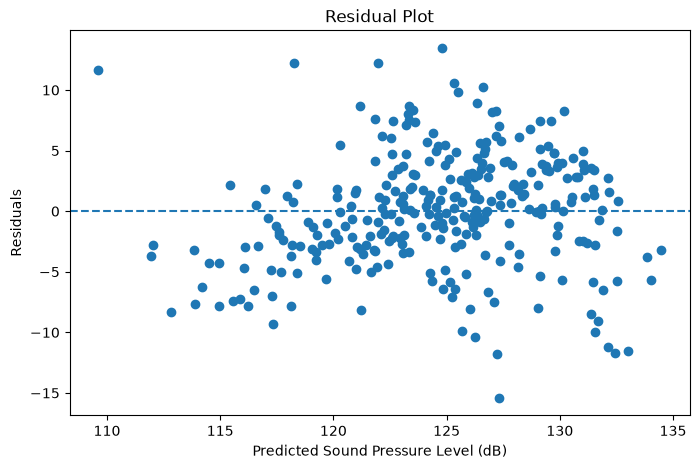

In [18]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Sound Pressure Level (dB)")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

## Model Interpretation

A Linear Regression model was developed to predict the Sound Pressure Level (SPL) of an airfoil using five input features:

- Frequency
- Angle of Attack
- Chord Length
- Free Stream Velocity
- Suction Side Displacement Thickness

The dataset was divided into 80% training data and 20% testing data.

### Model Performance

The model achieved the following results:

- Mean Absolute Error (MAE): 3.6724
- Mean Squared Error (MSE): 22.1286
- Root Mean Squared Error (RMSE): 4.7041
- R² Score: 0.5583

### Interpretation of Results

The MAE indicates that the model's predictions differ from actual sound pressure levels by approximately 3.67 dB on average.

The R² score of 0.5583 indicates that the model explains approximately 55.83% of the variation in sound pressure level.

The results show that Linear Regression can capture some of the relationship between airfoil characteristics and sound pressure level. However, its predictive performance has room for improvement.

### Conclusion

The project successfully demonstrates the application of Linear Regression to airfoil self-noise prediction. The model provides a baseline for predicting sound pressure levels using physical and aerodynamic parameters.

Further improvements may be possible through additional feature analysis and more advanced machine learning techniques.